# Case C · Monthly demand forecasting

## CRISP-DM question

Can a simple seasonal model improve a one-year operational plan over last
year's same-month baseline?

**Learning objective:** keep chronology intact, create forecasts from past
information only, and compare models with MAE and MAPE.


In [1]:
from pathlib import Path
import sys

ROOT = Path.cwd()
if not (ROOT / "src").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "src"))

import pandas as pd
from IPython.display import Image, display

from tutorial.data import write_datasets

paths = write_datasets(ROOT / "data")
ROOT

WindowsPath('C:/Users/Xie Yulong/Documents/ChatGPT/面试/data-science-crisp-dm-tutorial')

In [2]:
df = pd.read_csv(paths["demand"], parse_dates=["month"])
df.tail()

,month,demand
55,2025-08-01,172.5
56,2025-09-01,173.3
57,2025-10-01,185.3
58,2025-11-01,177.5
59,2025-12-01,194.5


<Axes: title={'center': 'Synthetic monthly demand'}, xlabel='month', ylabel='Demand'>

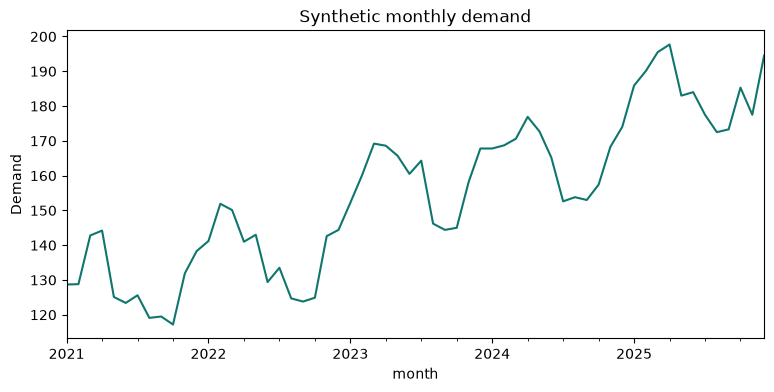

In [3]:
df.set_index("month").plot(
    figsize=(9, 4),
    title="Synthetic monthly demand",
    ylabel="Demand",
    color="#0f766e",
    legend=False,
)

## Chronological validation

The final 12 months are the test period. A random split would allow future
information to leak into the training set.


In [4]:
from tutorial.examples import run_demand_example

demand = run_demand_example()

pd.DataFrame({
    "seasonal naive": demand.seasonal_naive_metrics,
    "seasonal linear": demand.seasonal_linear_metrics,
}).T

,mae,mape
seasonal naive,19.650,10.622
seasonal linear,5.326,2.861


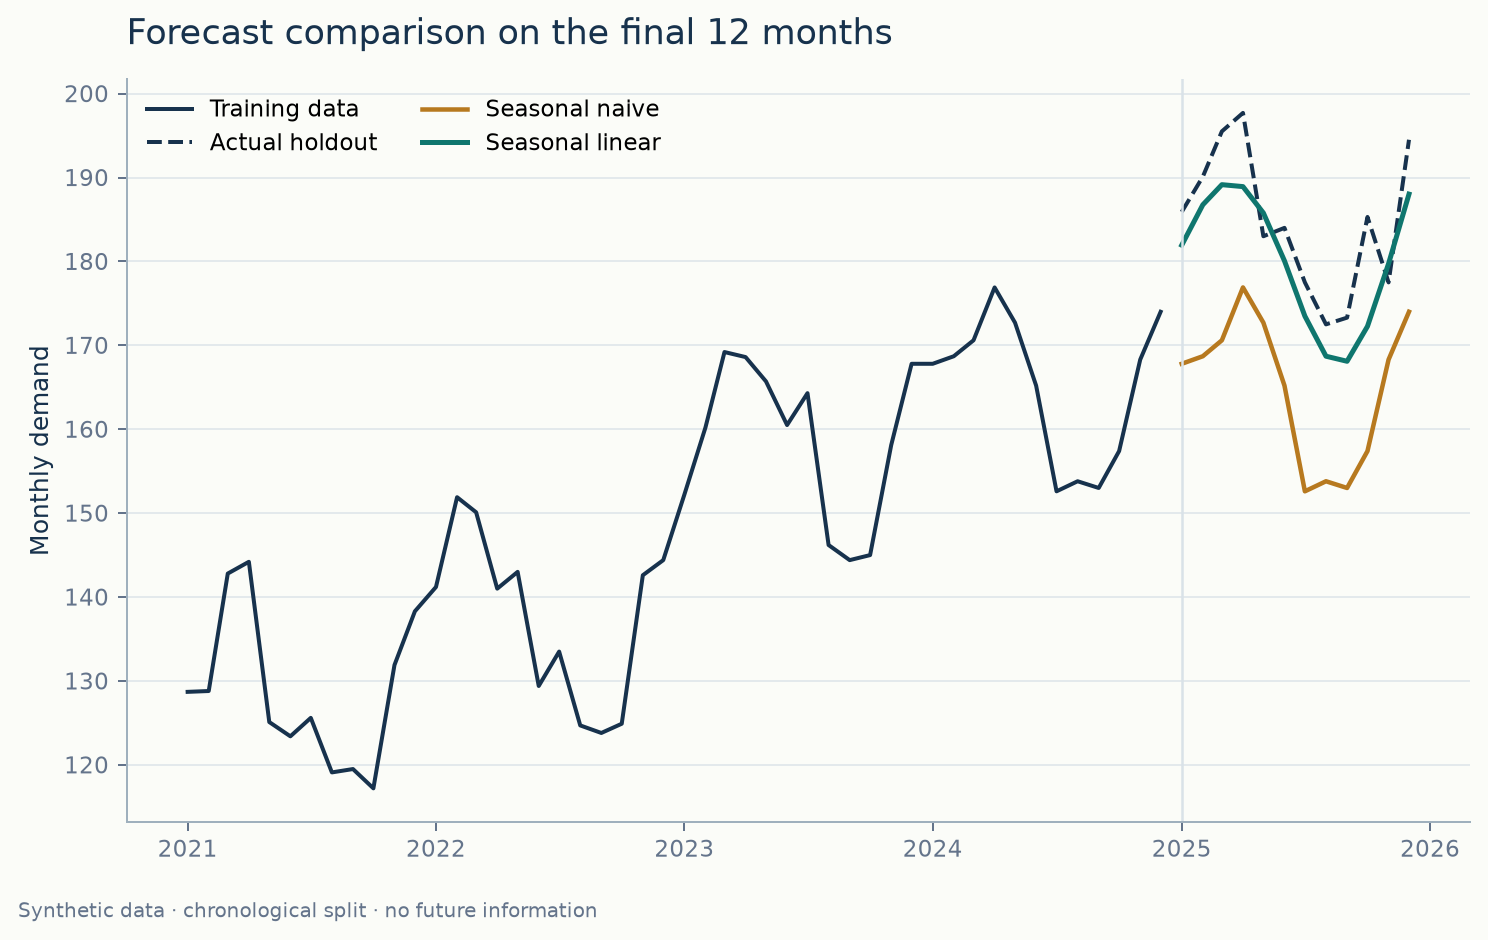

In [5]:
display(Image(filename=str(ROOT / "assets" / "img" / "demand-forecast.png")))

## Interpretation and exercise

MAPE becomes unstable when actual demand approaches zero. For real operational
data, inspect the cost of over- and under-forecasting rather than choosing a
metric by habit.

Exercise: change the holdout from 12 to 6 months and explain why the model
comparison may change.
